# Unveiling the Android App Market: Google Play Store Analysis
**Task 4 | Name: ____________ | Roll No: ____________**

**Goal:** clean the messy Play Store data, explore categories, ratings, size/installs and pricing, run VADER sentiment analysis on user reviews, and finish with 3 data-driven insights for a developer planning a new app.

**Data (Kaggle: "Google Play Store Apps" by lava18):** download and place these two files next to this notebook:
- `googleplaystore.csv`
- `googleplaystore_user_reviews.csv`

**Install once:** `pip install pandas numpy matplotlib seaborn plotly scipy vaderSentiment`

## 1. Setup and loading the two datasets

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from scipy.stats import spearmanr
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

APPS_PATH = "googleplaystore.csv"
REVIEWS_PATH = "googleplaystore_user_reviews.csv"

apps_raw = pd.read_csv(APPS_PATH)
reviews_raw = pd.read_csv(REVIEWS_PATH)
print("Apps:", apps_raw.shape, "| Reviews:", reviews_raw.shape)
apps_raw.head()

Apps: (10841, 13) | Reviews: (64295, 5)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [1]:
apps_raw.info()
reviews_raw.head()

NameError: name 'apps_raw' is not defined

## 2. Data cleaning
Problems we expect: one malformed row (columns shifted), duplicate apps, numbers stored as text (`Installs` = "10,000+", `Price` = "$4.99", `Size` = "19M" / "Varies with device"), and nulls in `Rating`.

In [ ]:
apps = apps_raw.copy()
print("Nulls BEFORE cleaning:\n", apps.isna().sum()[lambda s: s > 0], "\n")

# 1) Malformed row(s): real categories look like ART_AND_DESIGN
bad = ~apps["Category"].astype(str).str.match(r"^[A-Z_]+$")
print("Malformed rows removed:", bad.sum())
apps = apps[~bad].copy()

# 2) Types: Reviews, Installs, Price, Size, Last Updated
apps["Reviews"] = pd.to_numeric(apps["Reviews"], errors="coerce")
apps["Installs"] = pd.to_numeric(apps["Installs"].astype(str).str.replace(r"[+,]", "", regex=True), errors="coerce")
apps["Price"] = pd.to_numeric(apps["Price"].astype(str).str.replace("$", "", regex=False), errors="coerce")
apps["Rating"] = pd.to_numeric(apps["Rating"], errors="coerce")

def parse_size(s):
    """'19M' -> 19.0 (MB), '201k' -> 0.196 (MB), 'Varies with device' -> NaN"""
    s = str(s).strip().replace(",", "")
    try:
        if s.endswith("M"): return float(s[:-1])
        if s.endswith("k"): return float(s[:-1]) / 1024
    except ValueError:
        pass
    return np.nan
apps["Size_MB"] = apps["Size"].apply(parse_size)
apps["Last Updated"] = pd.to_datetime(apps["Last Updated"], errors="coerce")

# 3) Duplicates: same app listed several times -> keep the row with the most reviews
print("Fully identical duplicate rows:", apps.duplicated().sum())
print("Duplicate app names:", apps.duplicated("App").sum())
apps = apps.sort_values("Reviews", ascending=False).drop_duplicates("App").reset_index(drop=True)

# 4) Nulls
apps["Type"] = apps["Type"].fillna(apps["Price"].map(lambda p: "Free" if p == 0 else "Paid"))
apps = apps.dropna(subset=["Installs", "Price"])
# Rating nulls are kept (they are unrated apps); rating analyses use the subset below
rated = apps.dropna(subset=["Rating"])

print(f"\nClean apps: {len(apps):,} | with a rating: {len(rated):,}")
print("Nulls AFTER cleaning:\n", apps.isna().sum()[lambda s: s > 0])
apps[["App", "Category", "Rating", "Reviews", "Size_MB", "Installs", "Type", "Price"]].head()

Nulls BEFORE cleaning:
 Rating            1474
Type                 1
Content Rating       1
Current Ver          8
Android Ver          3
dtype: int64 

Malformed rows removed: 1
Fully identical duplicate rows: 483
Duplicate app names: 1181



Clean apps: 9,659 | with a rating: 8,196
Nulls AFTER cleaning:
 Rating         1463
Current Ver       8
Android Ver       2
Size_MB        1228
dtype: int64


,App,Category,Rating,Reviews,Size_MB,Installs,Type,Price
0,Facebook,SOCIAL,4.1,78158306,NaN,1000000000,Free,0.0
1,WhatsApp Messenger,COMMUNICATION,4.4,69119316,NaN,1000000000,Free,0.0
2,Instagram,SOCIAL,4.5,66577446,NaN,1000000000,Free,0.0
3,Messenger – Text and Video Chat for Free,COMMUNICATION,4.0,56646578,NaN,1000000000,Free,0.0
4,Clash of Clans,GAME,4.6,44893888,98.0,100000000,Free,0.0


**Observations (cleaning).** The raw file has 10,841 rows. One malformed row (columns shifted, rating of 19) was removed, and 1,181 repeated app names were dropped (the copy with the most reviews is kept), leaving **9,659 unique apps**, of which **8,196 have a rating**. Unrated apps are kept for the non-rating analyses. `Size` is missing for 1,228 apps ("Varies with device"), which is kept as NaN rather than guessed.

## 3. Category analysis: where is the market saturated?

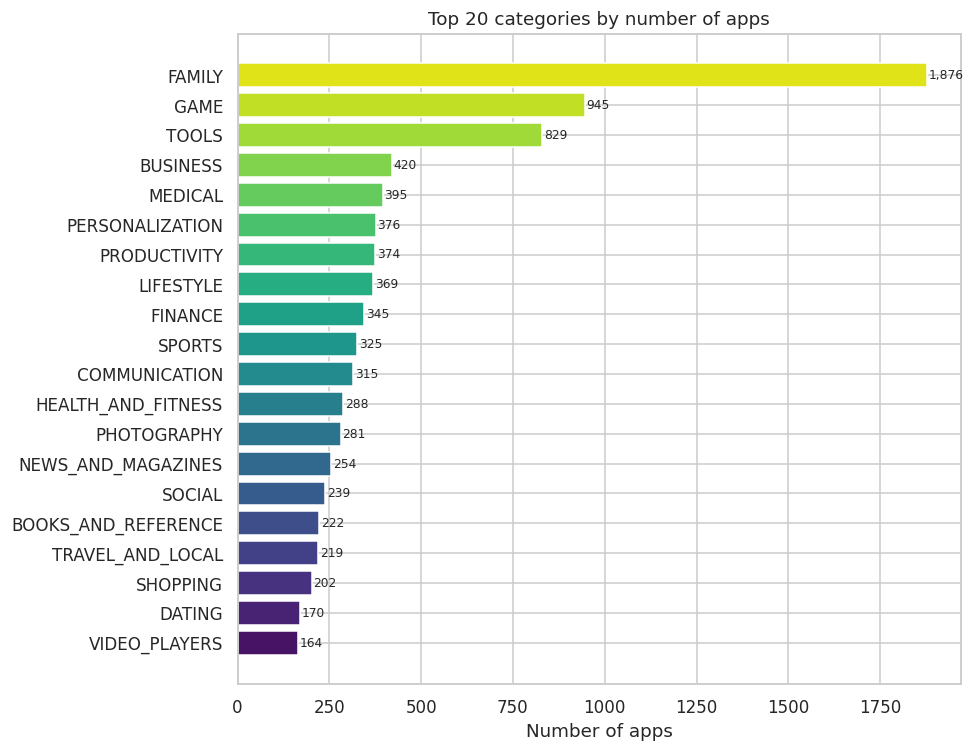

Top 5 categories hold 46.2% of all apps


,n_apps,avg_rating,median_installs,total_installs,share_pct,installs_per_app
Category,,,,,,
FAMILY,1876,4.18,50000.0,6231542505,19.42,3321717.75
GAME,945,4.24,1000000.0,13447924415,9.78,14230607.85
TOOLS,829,4.04,50000.0,8102771915,8.58,9774151.89
BUSINESS,420,4.10,1000.0,697164865,4.35,1659916.35
MEDICAL,395,4.17,1000.0,38293077,4.09,96944.50
PERSONALIZATION,376,4.33,10000.0,1532494782,3.89,4075783.99
PRODUCTIVITY,374,4.18,100000.0,5793091369,3.87,15489549.11
LIFESTYLE,369,4.09,10000.0,503823539,3.82,1365375.44
FINANCE,345,4.12,10000.0,455348734,3.57,1319851.40


In [ ]:
cat = (apps.groupby("Category")
       .agg(n_apps=("App", "count"), avg_rating=("Rating", "mean"),
            median_installs=("Installs", "median"), total_installs=("Installs", "sum"))
       .assign(share_pct=lambda d: d.n_apps / d.n_apps.sum() * 100,
               installs_per_app=lambda d: d.total_installs / d.n_apps)
       .sort_values("n_apps", ascending=False))

top = cat.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.n_apps, color=sns.color_palette("viridis", len(top)))
for i, v in enumerate(top.n_apps): ax.text(v + 5, i, f"{v:,}", va="center", fontsize=8)
ax.set_title("Top 20 categories by number of apps"); ax.set_xlabel("Number of apps")
plt.tight_layout(); plt.show()

print(f"Top 5 categories hold {cat.share_pct.head(5).sum():.1f}% of all apps")
cat.head(10).round(2)

**Observations (categories).** The market is concentrated: the top 5 categories hold **46.2%** of all apps, led by FAMILY (1,876 apps, 19.4%), GAME (945) and TOOLS (829). Crowding alone is not the same as saturation: GAME is crowded but has a median of 1M installs per app, while BUSINESS (420 apps) and MEDICAL (395 apps) are both crowded **and** have a median of only 1,000 installs, which makes them the toughest markets for a newcomer.

In [ ]:
# Saturation = lots of supply (apps) relative to demand (installs per app)
sat = cat[cat.n_apps >= 30].copy()
sat["supply_rank"] = sat.n_apps.rank(ascending=False)
sat["demand_per_app_rank"] = sat.installs_per_app.rank(ascending=False)
print("MOST SATURATED (many apps, low installs per app):")
display(sat.sort_values(["supply_rank"]).head(5)[["n_apps", "installs_per_app", "median_installs"]].round(0))
print("LEAST SATURATED (high installs per app):")
display(sat.sort_values("installs_per_app", ascending=False).head(5)[["n_apps", "installs_per_app", "median_installs"]].round(0))

MOST SATURATED (many apps, low installs per app):


,n_apps,installs_per_app,median_installs
Category,,,
FAMILY,1876,3321718.0,50000.0
GAME,945,14230608.0,1000000.0
TOOLS,829,9774152.0,50000.0
BUSINESS,420,1659916.0,1000.0
MEDICAL,395,96944.0,1000.0


LEAST SATURATED (high installs per app):


,n_apps,installs_per_app,median_installs
Category,,,
COMMUNICATION,315,35042147.0,100000.0
VIDEO_PLAYERS,164,23975017.0,1000000.0
SOCIAL,239,22961790.0,100000.0
PHOTOGRAPHY,281,16577038.0,1000000.0
PRODUCTIVITY,374,15489549.0,100000.0


## 4. Ratings analysis

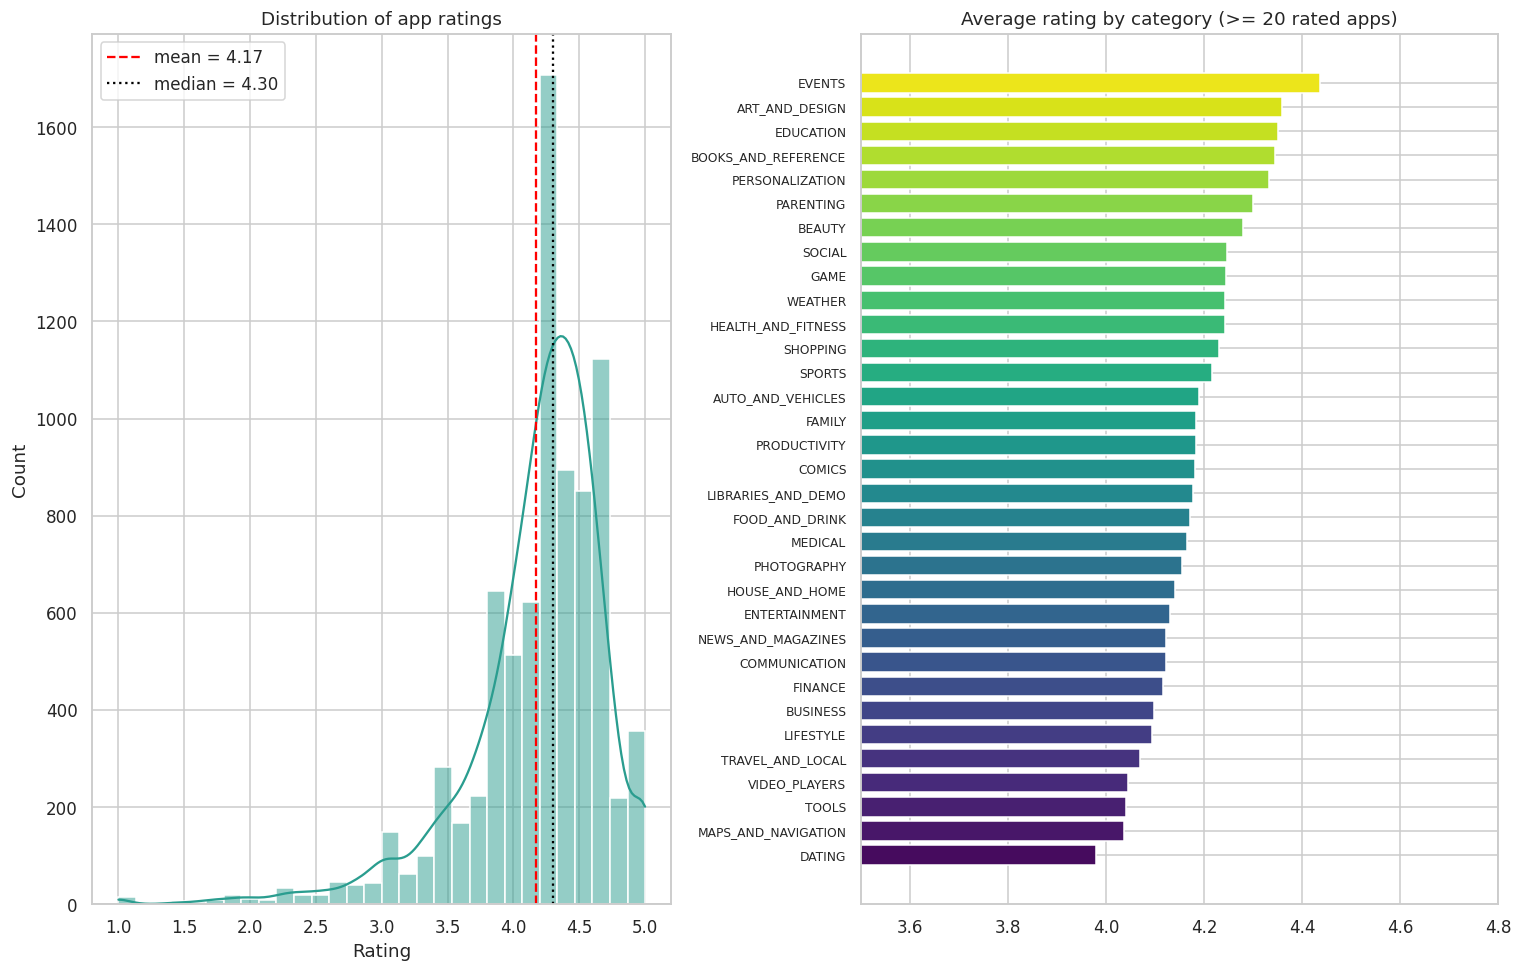

Skewness: -1.75  -> ratings pile up at the high end (4.0-4.7)
Best: EVENTS 4.44 | Worst: DATING 3.98


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 9), gridspec_kw={"width_ratios": [1, 1.1]})
sns.histplot(rated.Rating, bins=30, kde=True, ax=ax[0], color="#2a9d8f")
ax[0].axvline(rated.Rating.mean(), color="red", ls="--", label=f"mean = {rated.Rating.mean():.2f}")
ax[0].axvline(rated.Rating.median(), color="black", ls=":", label=f"median = {rated.Rating.median():.2f}")
ax[0].set_title("Distribution of app ratings"); ax[0].legend()

avg = (rated.groupby("Category").agg(avg_rating=("Rating", "mean"), n=("App", "count"))
       .query("n >= 20").sort_values("avg_rating"))
ax[1].barh(avg.index, avg.avg_rating, color=sns.color_palette("viridis", len(avg)))
ax[1].set_xlim(3.5, 4.8); ax[1].set_title("Average rating by category (>= 20 rated apps)")
ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
print(f"Skewness: {rated.Rating.skew():.2f}  -> ratings pile up at the high end (4.0-4.7)")
print("Best:", avg.avg_rating.idxmax(), round(avg.avg_rating.max(), 2), "| Worst:", avg.avg_rating.idxmin(), round(avg.avg_rating.min(), 2))

**Observations (ratings).** Ratings are strongly left-skewed (skewness about -1.75): mean 4.17, median 4.30, and 76.7% of rated apps score 4.0 or higher. A 4.0 is therefore only average. Category averages are tightly bunched, from EVENTS (4.44) down to DATING (3.98), so category choice moves the expected rating by less than half a star.

## 5. Size vs. installs

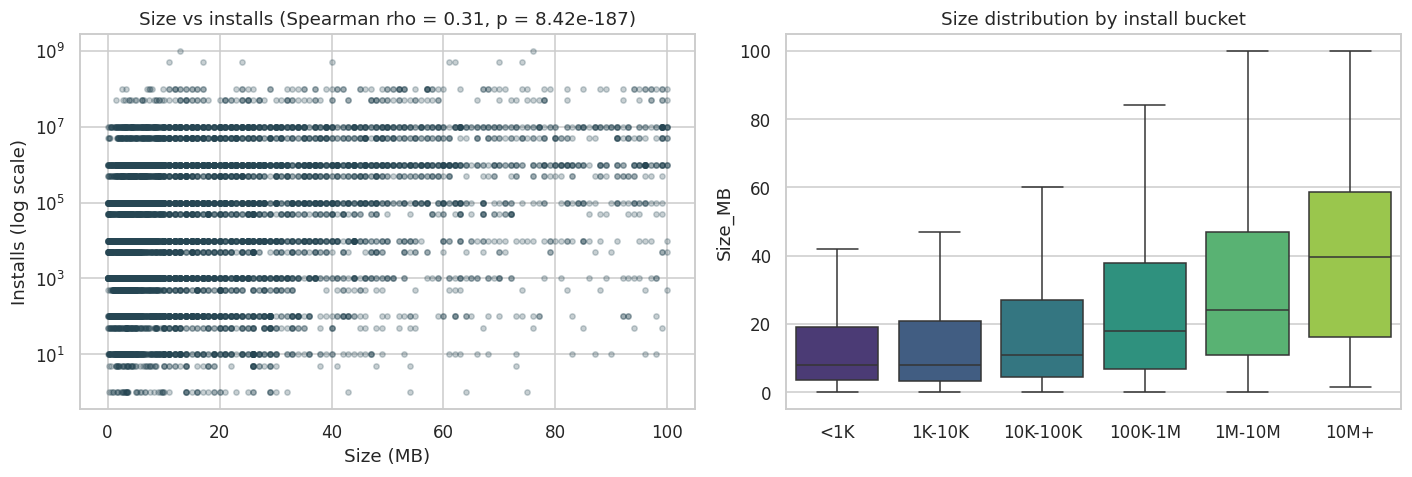

Spearman rho = 0.31 -> weak-to-moderate positive relationship. Bigger apps tend to have somewhat more installs, but the spread is huge at every size: size alone does not explain popularity.


In [ ]:
si = apps.dropna(subset=["Size_MB"]).query("Installs > 0")
rho, p = spearmanr(si.Size_MB, si.Installs)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(si.Size_MB, si.Installs, alpha=0.25, s=12, color="#264653")
ax[0].set_yscale("log"); ax[0].set_xlabel("Size (MB)"); ax[0].set_ylabel("Installs (log scale)")
ax[0].set_title(f"Size vs installs (Spearman rho = {rho:.2f}, p = {p:.3g})")

si = si.assign(installs_bucket=pd.cut(si.Installs, [0, 1e3, 1e4, 1e5, 1e6, 1e7, 1e10],
               labels=["<1K", "1K-10K", "10K-100K", "100K-1M", "1M-10M", "10M+"]))
sns.boxplot(data=si, x="installs_bucket", y="Size_MB", ax=ax[1], showfliers=False, palette="viridis")
ax[1].set_title("Size distribution by install bucket"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()
strength = "weak" if abs(rho) < 0.3 else "weak-to-moderate" if abs(rho) < 0.5 else "moderate/strong"
print(f"Spearman rho = {rho:.2f} -> {strength} positive relationship. Bigger apps tend to have somewhat more installs, "
      "but the spread is huge at every size: size alone does not explain popularity.")

**Observations (size vs installs).** Spearman rho is about 0.31, a weak-to-moderate positive relationship. Big apps (mostly games and feature-rich apps) tend to have more installs, but the scatter shows enormous spread at every size, so size alone does not explain popularity. Spearman is used rather than Pearson because installs are extremely skewed.

## 6. Pricing analysis

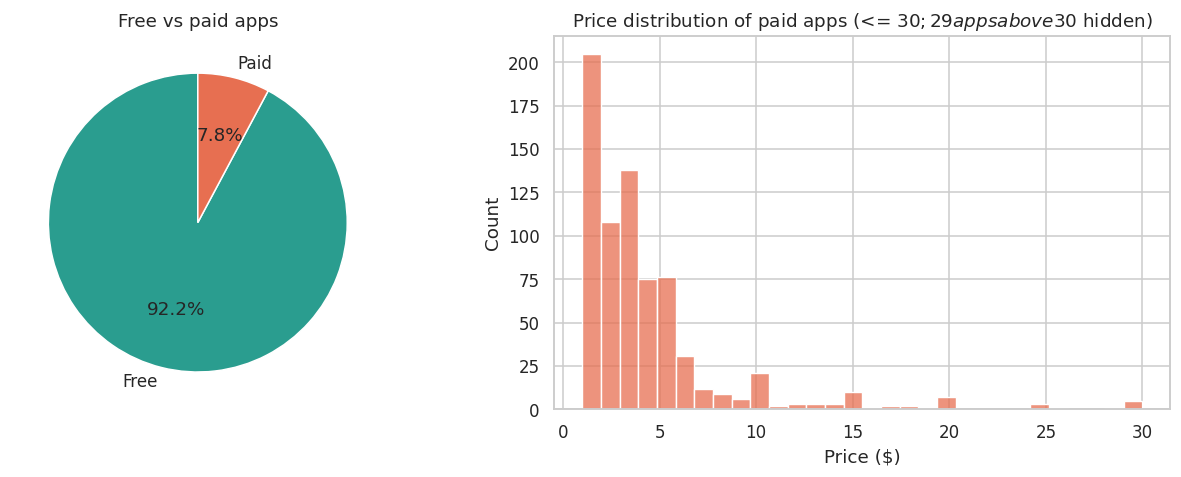

Paid apps: 754 | median price $2.99 | mean $14.06
Avg rating: {'Free': 4.17, 'Paid': 4.26}
Median installs: {'Free': 100000.0, 'Paid': 1000.0}


In [ ]:
type_counts = apps.Type.value_counts()
paid = apps[(apps.Type == "Paid") & (apps.Price > 0)]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", colors=["#2a9d8f", "#e76f51"], startangle=90)
ax[0].set_title("Free vs paid apps")
sns.histplot(paid[paid.Price <= 30].Price, bins=30, ax=ax[1], color="#e76f51")
ax[1].set_title(f"Price distribution of paid apps (<= $30; {(paid.Price > 30).sum()} apps above $30 hidden)")
ax[1].set_xlabel("Price ($)")
plt.tight_layout(); plt.show()

print(f"Paid apps: {len(paid):,} | median price ${paid.Price.median():.2f} | mean ${paid.Price.mean():.2f}")
print("Avg rating:", apps.groupby("Type").Rating.mean().round(2).to_dict())
print("Median installs:", apps.groupby("Type").Installs.median().to_dict())

**Observations (pricing).** The store is overwhelmingly free (**92.2%**); only 754 apps (about 7.8%) are paid, and most of those cost under $3 (median $2.99). Paid apps have a slightly higher average rating (4.26 vs 4.17), but a far lower median install count (1,000 vs 100,000): users who pay are fewer but happier, or at least self-selected.

Excluding 20 novelty apps priced above $100 (e.g. 'I am Rich'-style apps): ['I am rich', 'I Am Rich Premium', 'I am Rich Plus', "💎 I'm rich"]


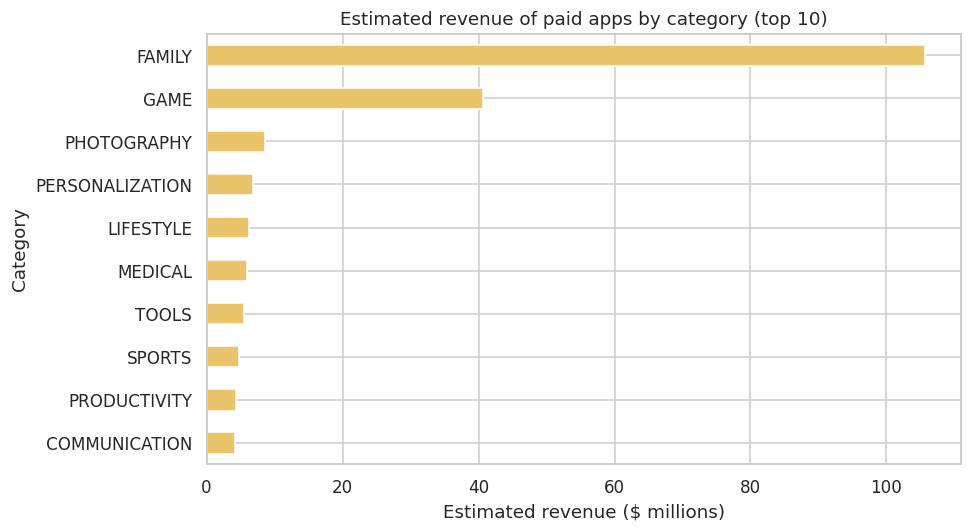

,est_revenue,paid_apps
Category,,
FAMILY,105741086.0,181
GAME,40688637.0,82
PHOTOGRAPHY,8547768.0,19
PERSONALIZATION,6796948.0,81
LIFESTYLE,6205149.0,13
MEDICAL,5956237.0,81
TOOLS,5464821.0,78
SPORTS,4706212.0,24
PRODUCTIVITY,4313375.0,27


In [ ]:
# Revenue ESTIMATE = price x installs (lower bound: Installs is a bucket floor; ignores in-app purchases,
# ads, refunds and Google's ~30% store cut. Use for ranking, not as real revenue.)
novelty = paid[paid.Price > 100]
print(f"Excluding {len(novelty)} novelty apps priced above $100 (e.g. 'I am Rich'-style apps): {novelty.App.head(4).tolist()}")
paid = paid[paid.Price <= 100].assign(est_revenue=lambda d: d.Price * d.Installs)
rev = paid.groupby("Category").agg(est_revenue=("est_revenue", "sum"), paid_apps=("App", "count")).sort_values("est_revenue", ascending=False)

ax = rev.head(10).iloc[::-1].est_revenue.div(1e6).plot.barh(figsize=(9, 5), color="#e9c46a")
ax.set_title("Estimated revenue of paid apps by category (top 10)"); ax.set_xlabel("Estimated revenue ($ millions)")
plt.tight_layout(); plt.show()
rev.head(10).round(0)

**Observations (revenue estimate).** By price x installs, FAMILY (about $106M) and GAME (about $41M) are far ahead of every other category. 20 novelty apps priced above $100 (the "I am Rich" family, up to $400) were excluded because they would distort the ranking. This is only a lower-bound proxy: install counts are bucket floors, and in-app purchases, ads, refunds and the store's commission are ignored.

## 7. Sentiment analysis of user reviews (VADER)
VADER returns a compound score in [-1, 1]. Standard thresholds: **>= 0.05 positive, <= -0.05 negative, otherwise neutral**.

Reviews kept: 29,692 of 64,295


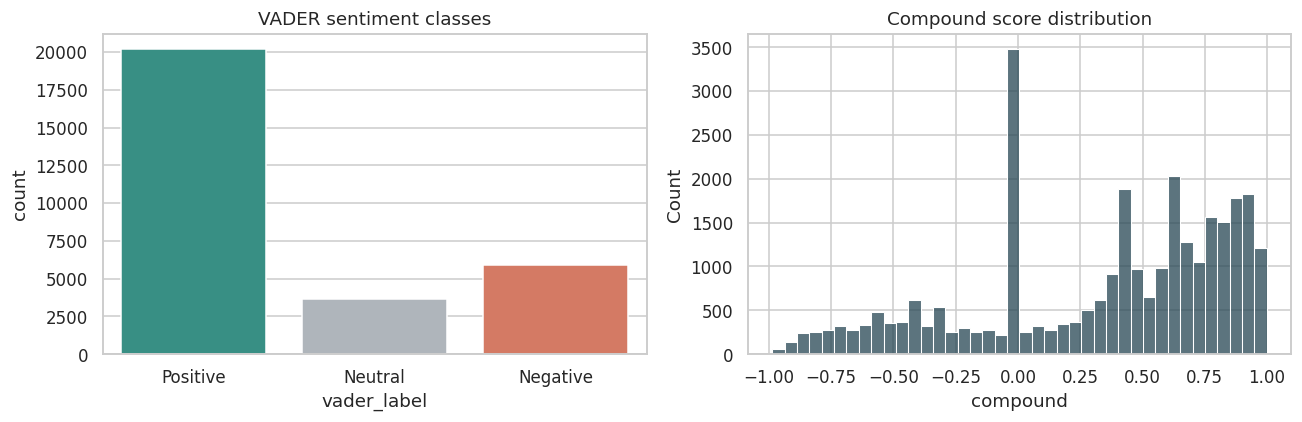

vader_label
Positive    68.0
Negative    19.8
Neutral     12.2
Name: proportion, dtype: float64

VADER vs dataset label (row %):


vader_label,Negative,Neutral,Positive
Sentiment,,,
Negative,59.2,8.9,31.9
Neutral,17.9,50.1,32.0
Positive,7.1,4.6,88.3


In [ ]:
reviews = (reviews_raw.dropna(subset=["Translated_Review"])
           .drop_duplicates(["App", "Translated_Review"]).reset_index(drop=True))
print(f"Reviews kept: {len(reviews):,} of {len(reviews_raw):,}")

sia = SentimentIntensityAnalyzer()
reviews["compound"] = reviews.Translated_Review.astype(str).apply(lambda t: sia.polarity_scores(t)["compound"])
reviews["vader_label"] = pd.cut(reviews.compound, [-1.01, -0.05, 0.05, 1.01], labels=["Negative", "Neutral", "Positive"], right=False)
# edge: score exactly 0.05 -> positive; pd.cut with right=False handles [0.05, 1.01)

order = ["Positive", "Neutral", "Negative"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=reviews, x="vader_label", order=order, ax=ax[0], palette=["#2a9d8f", "#adb5bd", "#e76f51"])
ax[0].set_title("VADER sentiment classes")
sns.histplot(reviews.compound, bins=40, ax=ax[1], color="#264653"); ax[1].set_title("Compound score distribution")
plt.tight_layout(); plt.show()
print((reviews.vader_label.value_counts(normalize=True) * 100).round(1))

# Sanity check vs the label shipped with the dataset
print("\nVADER vs dataset label (row %):")
display((pd.crosstab(reviews.Sentiment, reviews.vader_label, normalize="index") * 100).round(1))

**Observations (sentiment).** After dropping empty and duplicate reviews, 29,692 reviews remain. VADER classifies **68.0% positive, 19.8% negative and 12.2% neutral**. It agrees with the dataset's own label for 88% of positive reviews but only 59% of negative and 50% of neutral ones; it tends to read mixed or sarcastic reviews as positive. Treat negative percentages as conservative.

## 8. Sentiment by category

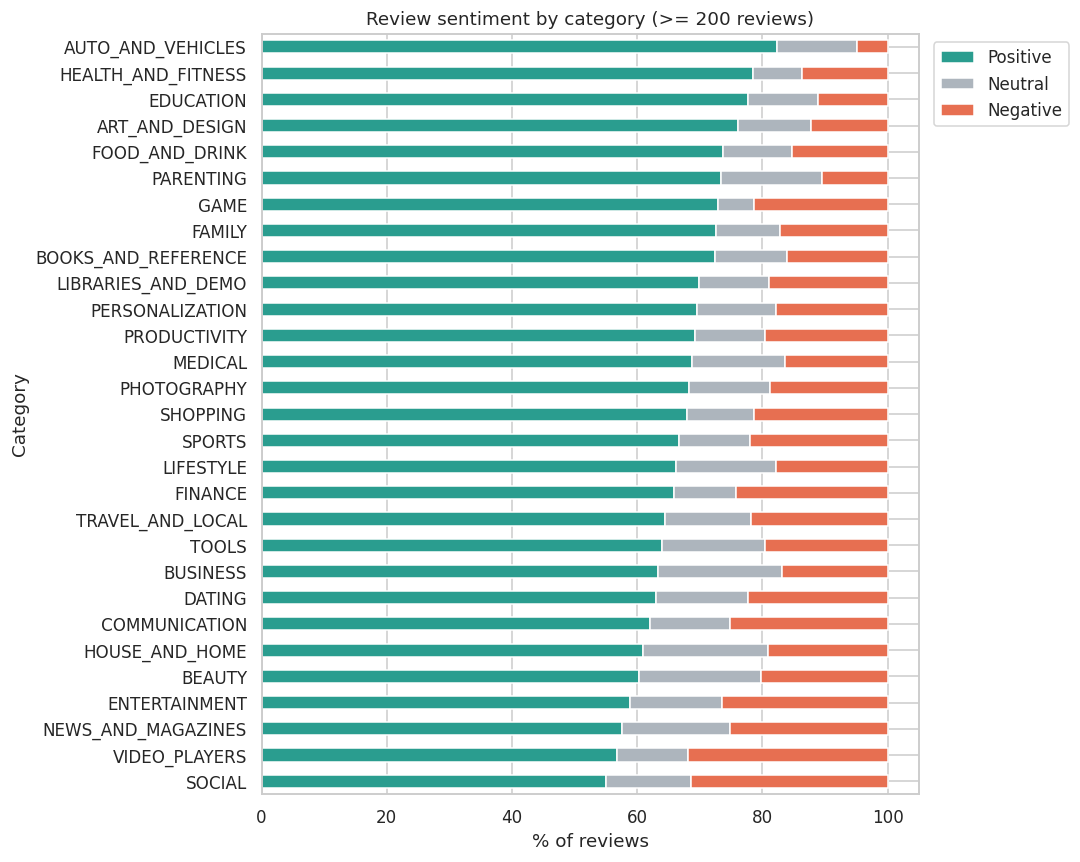

Most positive: AUTO_AND_VEHICLES (82.3% positive)
Most negative: VIDEO_PLAYERS (31.9% negative)


In [ ]:
rv = reviews.merge(apps[["App", "Category"]], on="App", how="inner")
sent = (pd.crosstab(rv.Category, rv.vader_label, normalize="index") * 100)
sent["n_reviews"] = rv.groupby("Category").size()
sent["mean_compound"] = rv.groupby("Category").compound.mean()
sent = sent[sent.n_reviews >= 200].sort_values("Positive")

ax = sent[order].plot.barh(stacked=True, figsize=(10, 8), color=["#2a9d8f", "#adb5bd", "#e76f51"])
ax.set_xlabel("% of reviews"); ax.set_title("Review sentiment by category (>= 200 reviews)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

print("Most positive:", sent.Positive.idxmax(), f"({sent.Positive.max():.1f}% positive)")
print("Most negative:", sent.Negative.idxmax(), f"({sent.Negative.max():.1f}% negative)")

**Observations (sentiment by category).** AUTO_AND_VEHICLES has the happiest reviewers (82% positive) and VIDEO_PLAYERS the most critical (about 32% negative). Only categories with at least 200 reviews are shown, and reviews cover just a subset of apps, so small categories are excluded.

## 9. Interactive visualisations (Plotly)

In [ ]:
# Market map: supply vs quality vs demand, enriched with sentiment
mm = cat.join(sent[["Positive", "Negative", "mean_compound"]], how="left").reset_index()
mm = mm[mm.n_apps >= 30]
fig = px.scatter(mm, x="n_apps", y="avg_rating", size="total_installs", color="mean_compound",
                 hover_name="Category", hover_data={"n_apps": ":,", "installs_per_app": ":,.0f", "Positive": ":.1f"},
                 color_continuous_scale="RdYlGn", size_max=55,
                 title="Market map: bubble size = total installs, colour = mean review sentiment")
fig.update_layout(xaxis_title="Number of apps (supply / saturation)", yaxis_title="Average rating", height=600)
fig.show()

In [ ]:
# Drill-down: installs by category -> content rating -> type
sun = apps[apps.Category.isin(cat.head(8).index)].groupby(["Category", "Type"], as_index=False).agg(apps=("App", "count"))
px.sunburst(sun, path=["Category", "Type"], values="apps", title="Top 8 categories: free vs paid composition").show()

## 10. Conclusion: 3 data-driven insights for a new-app developer
The numbers below are computed from your run, so they always match the data.

In [ ]:
cands = cat[cat.n_apps >= 30]
med_n = cands.n_apps.median()
hard = cands[cands.n_apps >= med_n].sort_values("median_installs").head(2)
open_ = cands[cands.n_apps < med_n].sort_values(["median_installs", "installs_per_app"], ascending=False).head(3)
fmt = lambda df: ", ".join(f"{i} ({int(r.n_apps):,} apps, median {int(r.median_installs):,} installs)" for i, r in df.iterrows())
free_pct = (apps.Type == "Free").mean() * 100
top_rev = rev.est_revenue.idxmax()

print(f"""INSIGHT 1 - Choose your category by supply vs demand (use MEDIAN installs, because averages are distorted by giants like Facebook).
  Crowded AND low demand (avoid or differentiate hard): {fmt(hard)}.
  Less crowded with strong demand (opportunity): {fmt(open_)}.
  Largest category overall: '{cands.n_apps.idxmax()}' with {cands.n_apps.max():,} apps ({cands.share_pct.max():.1f}% of the store).

INSIGHT 2 - Launch free and monetise through ads / in-app purchases.
  {free_pct:.1f}% of apps are free. Median installs: free = {apps[apps.Type=='Free'].Installs.median():,.0f} vs paid = {apps[apps.Type=='Paid'].Installs.median():,.0f}.
  Paid apps cost a median of ${paid.Price.median():.2f} and the biggest estimated paid revenue is in '{top_rev}',
  but that is a proxy (price x installs), so paid models only pay off in a few niches.

INSIGHT 3 - Don't obsess over app size; obsess over quality and the category's sentiment bar.
  Size vs installs Spearman rho = {rho:.2f} ({strength}). Median rating is {rated.Rating.median():.1f}, so 4.0 is merely average.
  Users are most positive in '{sent.Positive.idxmax()}' ({sent.Positive.max():.0f}% positive) and most critical in
  '{sent.Negative.idxmax()}' ({sent.Negative.max():.0f}% negative) -> expect the highest polish/support bar there.
""")

INSIGHT 1 - Choose your category by supply vs demand (use MEDIAN installs, because averages are distorted by giants like Facebook).
  Crowded AND low demand (avoid or differentiate hard): BUSINESS (420 apps, median 1,000 installs), MEDICAL (395 apps, median 1,000 installs).
  Less crowded with strong demand (opportunity): VIDEO_PLAYERS (164 apps, median 1,000,000 installs), ENTERTAINMENT (87 apps, median 1,000,000 installs), SHOPPING (202 apps, median 1,000,000 installs).
  Largest category overall: 'FAMILY' with 1,876 apps (19.4% of the store).

INSIGHT 2 - Launch free and monetise through ads / in-app purchases.
  92.2% of apps are free. Median installs: free = 100,000 vs paid = 1,000.
  Paid apps cost a median of $2.99 and the biggest estimated paid revenue is in 'FAMILY',
  but that is a proxy (price x installs), so paid models only pay off in a few niches.

INSIGHT 3 - Don't obsess over app size; obsess over quality and the category's sentiment bar.
  Size vs installs Spearman rho

### Final conclusion: 3 data-driven insights for a developer launching a new app

1. **Pick the category by demand per app, not by total installs.** FAMILY, GAME and TOOLS hold the most apps, and BUSINESS and MEDICAL are crowded with a median of only 1,000 installs per app. Categories such as **VIDEO_PLAYERS, ENTERTAINMENT and SHOPPING** have fewer apps than the typical category yet a median of 1M installs, which is the best supply/demand balance in the data. Caveat: VIDEO_PLAYERS also has the most negative reviews, so expect demanding users.
2. **Launch free.** 92.2% of apps are free and they have a median of 100,000 installs versus 1,000 for paid apps. Paid apps are rated slightly higher (4.26 vs 4.17), but reach is about 100x smaller, and most paid apps cost under $3. Paid pricing only pays off in a few niches (revenue is concentrated in FAMILY and GAME), so plan monetisation through ads or in-app purchases.
3. **Compete on quality, not on app size.** Size has only a weak-to-moderate link to installs (rho about 0.31), so adding features is not penalised. Ratings are skewed high (median 4.3, and 77% of apps are at 4.0 or above), so a 4.0 is merely average and reviews are the real differentiator. Sentiment is 68% positive overall but varies by category (AUTO_AND_VEHICLES 82% positive, VIDEO_PLAYERS 32% negative), so budget more polish and support in the harsher categories.

**Limitations:** the dataset is a 2018 snapshot; `Installs` are lower-bound buckets; revenue is a price x installs proxy; reviews cover only a subset of apps; VADER is a general-purpose lexicon, so sarcasm and domain slang can be misclassified.